# Building a Diabetic Retinopathy (DR) detection model using PyTorch

### import Libraries

In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchsummary import summary

### Load Dataset (APTOS Dataset)

In [2]:
# load labels
df = pd.read_csv("../../DR Dataset/train.csv")

/tmp/ipykernel_2676/3886185945.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, alpha=0.8, palette='bright')


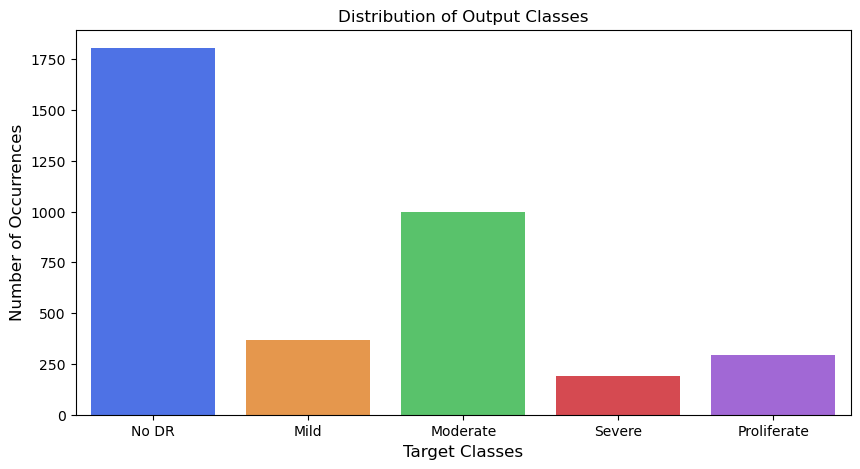

In [3]:
df.columns = ['id_code', 'diagnosis']  # Standardize column names
counts = df['diagnosis'].value_counts()  # Check class distribution
class_list = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferate']

for i, x in enumerate(class_list):
    counts[x] = counts.pop(i)

plt.figure(figsize=(10, 5))
sns.barplot(x=counts.index, y=counts.values, alpha=0.8, palette='bright')
plt.title('Distribution of Output Classes')
plt.ylabel('Number of Occurrences', fontsize=12)
plt.xlabel('Target Classes', fontsize=12)
plt.show()

### Visualize Images

In [6]:
def show_image(image_id, label):
    img = cv2.imread(f'../../DR Dataset/train_images/{image_id}.png')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # cv2.imshow(f"{label}",img)
    # cv2.waitKey(0)
    # cv2.destroyAllWindows()
    plt.imshow(img)
    plt.title(f"label: {label}")
    plt.axis("off")

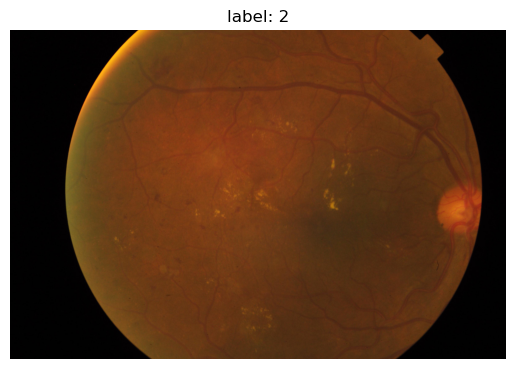

In [7]:
show_image(df['id_code'][0], df['diagnosis'][0])

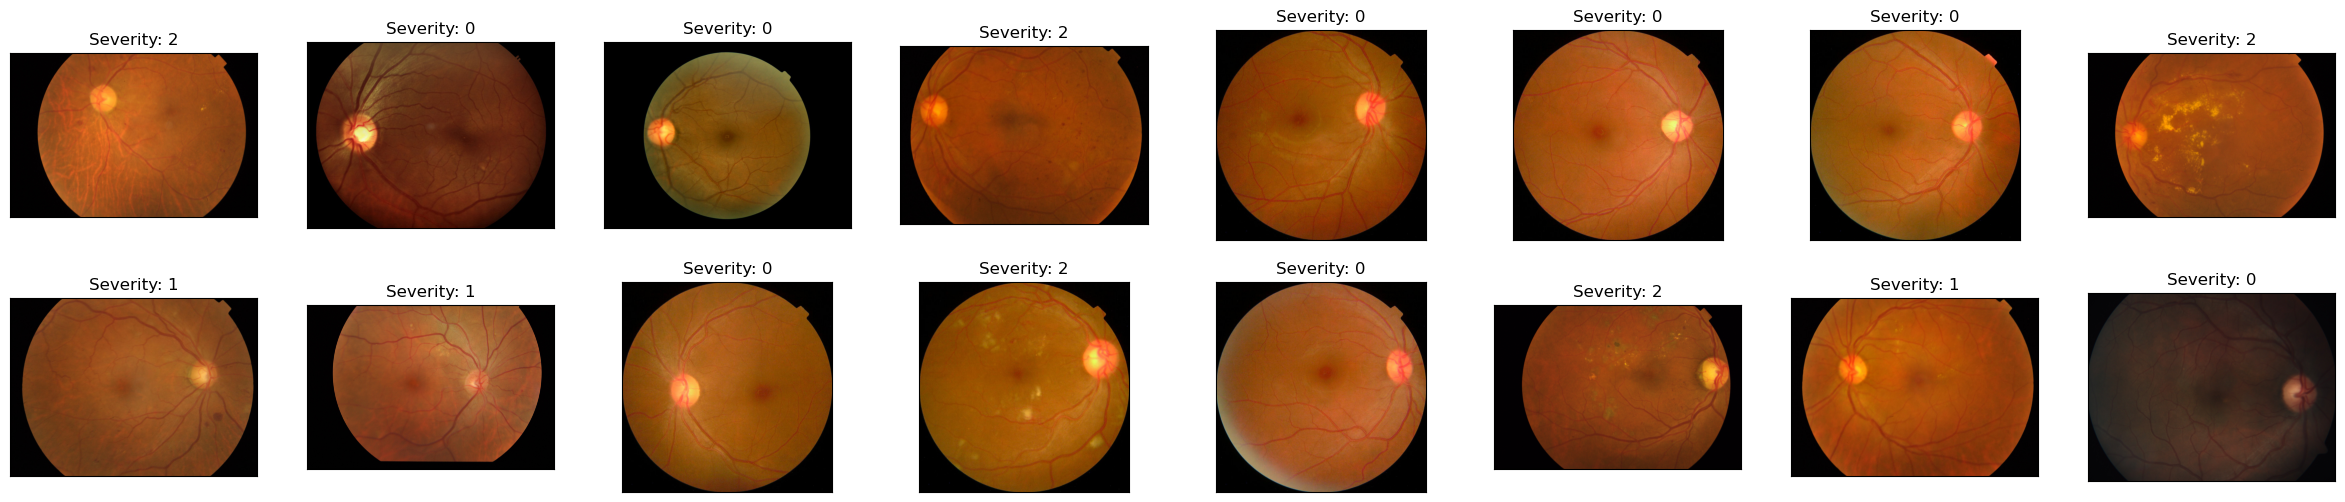

In [16]:
fig = plt.figure(figsize=(30, 6))
# display 20 images
train_imgs = os.listdir("../../DR Dataset/train_images")
for idx, img in enumerate(np.random.choice(train_imgs, 16)):
    ax = fig.add_subplot(2, 16//2, idx+1, xticks=[], yticks=[])
    im = Image.open("../../DR Dataset/train_images/" + img)
    plt.imshow(im)
    lab = df.loc[df['id_code'] == img.split('.')[0], 'diagnosis'].values[0]
    ax.set_title('Severity: %s'%lab)

### Preprocessing Pipeline

In [20]:
transform = A.Compose([
    A.Resize(256, 256),
    A.CLAHE(p=1.0),
    A.RandomBrightnessContrast(p=0.5),
    A.HorizontalFlip(p=0.5),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

### Create a PyTorch Dataset

In [22]:
class DRDataset(Dataset):

    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = f"../../DR Dataset/train_images/{self.df.iloc[idx]['id_code']}.png"
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        label = self.df.iloc[idx]['diagnosis']

        if self.transform:
            augment = self.transform(image=image)
            image = augment['image']

        return image, torch.tensor(label, dtype=torch.long)
        

In [27]:
# Split data
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['diagnosis'])
train_dataset = DRDataset(train_df, transform=transform)
val_dataset = DRDataset(val_df, transform=transform)

# stratify ensures balanced classes in train/val splits.

In [34]:
# Batch size (typically 16, 32, or 64 based on GPU memory)
batch_size = 32  

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=batch_size, 
    shuffle=True,  # Shuffle training data
    num_workers=2  # Parallel data loading (faster)
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=batch_size, 
    shuffle=False,  # No need to shuffle validation
    num_workers=2
)

# Package into a dictionary
dataloaders = {
    'train': train_loader,
    'val': val_loader
}

### Transfer Learning (ResNet18)

In [31]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 5)
summary(model.to('cuda'), (3, 256, 256))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 128, 128]           9,408
       BatchNorm2d-2         [-1, 64, 128, 128]             128
              ReLU-3         [-1, 64, 128, 128]               0
         MaxPool2d-4           [-1, 64, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          36,864
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
            Conv2d-8           [-1, 64, 64, 64]          36,864
       BatchNorm2d-9           [-1, 64, 64, 64]             128
             ReLU-10           [-1, 64, 64, 64]               0
       BasicBlock-11           [-1, 64, 64, 64]               0
           Conv2d-12           [-1, 64, 64, 64]          36,864
      BatchNorm2d-13           [-1, 64, 64, 64]             128
             ReLU-14           [-1, 64,

### Training Loop

In [32]:
# Define Loss & Optimmizer

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Class weights for imbalance
class_weights = torch.tensor([1.0, 2.0, 3.0, 4.0, 5.0], device='cuda')
criterion = nn.CrossEntropyLoss(weight=class_weights)

### Train the model

In [38]:
def train_model(model, dataloaders, criterion, optimizer, num_epochs=10):
    for epoch in range(num_epochs):
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to('cuda')
                labels = labels.to('cuda')

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)
            print(f"epoch:{epoch} {phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

In [39]:
train_model(model, dataloaders, criterion, optimizer)

epoch:0 train Loss: 1.0485 Acc: 0.6893
epoch:0 val Loss: 0.9449 Acc: 0.7422
epoch:1 train Loss: 0.8646 Acc: 0.7583
epoch:1 val Loss: 0.9350 Acc: 0.7121
epoch:2 train Loss: 0.8038 Acc: 0.7781
epoch:2 val Loss: 1.6614 Acc: 0.7149
epoch:3 train Loss: 0.7680 Acc: 0.7815
epoch:3 val Loss: 0.8161 Acc: 0.8035
epoch:4 train Loss: 0.6836 Acc: 0.8136
epoch:4 val Loss: 0.8334 Acc: 0.8008
epoch:5 train Loss: 0.6632 Acc: 0.8276
epoch:5 val Loss: 0.8269 Acc: 0.7749
epoch:6 train Loss: 0.6112 Acc: 0.8286
epoch:6 val Loss: 1.0352 Acc: 0.8035
epoch:7 train Loss: 0.5708 Acc: 0.8491
epoch:7 val Loss: 1.0673 Acc: 0.8022
epoch:8 train Loss: 0.5297 Acc: 0.8587
epoch:8 val Loss: 0.9784 Acc: 0.8131
epoch:9 train Loss: 0.5162 Acc: 0.8546
epoch:9 val Loss: 0.8459 Acc: 0.7940


### Evaluation

In [41]:
from sklearn.metrics import classification_report, cohen_kappa_score

y_true = []
y_pred = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to('cuda')
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

print(classification_report(y_true, y_pred))
print("Cohen's Kappa:", cohen_kappa_score(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.97      0.97       361
           1       0.75      0.45      0.56        74
           2       0.70      0.77      0.74       200
           3       0.39      0.18      0.25        39
           4       0.43      0.64      0.51        59

    accuracy                           0.79       733
   macro avg       0.65      0.60      0.60       733
weighted avg       0.80      0.79      0.79       733

Cohen's Kappa: 0.6866607971418622
